# PigsBF: exploring the raw `.mat` recordings

Eight pigs, one `.mat` file each. Each file holds a MATLAB struct `PigN` with 8 channels
(1-D signals of equal length within a pig, different lengths between pigs).

**Outline**
1. Setup and paths
2. Loading
3. Overview table (lengths, NaNs, ranges)
4. Missing data
5. Full-recording overview per pig
6. Zoom on a short window
7. Distributions across pigs
8. Out-of-range values (artifacts)
9. Periodicity and sampling rate

## 1. Setup and paths

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import scipy.io as sio
from scipy import signal
import matplotlib.pyplot as plt
from utils import find_root



ROOT    = find_root()
RAW_DIR = ROOT / "data" / "osfstorage-archive"
FIG_DIR = ROOT / "figures" / "exploration"
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("ROOT   :", ROOT)
print("RAW_DIR:", RAW_DIR, "| exists:", RAW_DIR.is_dir())

ROOT   : /Users/mboukaf/ThesisMB/Codes/PigsBF
RAW_DIR: /Users/mboukaf/ThesisMB/Codes/PigsBF/data/osfstorage-archive | exists: True


In [2]:
# Sampling rate: NOT stored in the .mat files.
# Estimated in section 9 (breathing ~600-750 samples, heartbeat ~190-230 samples per cycle).
# ⚠ Confirm against the dataset paper / OSF page before trusting any time axis.
FS = 250.0  # Hz (placeholder)

SINGLE = "#2a78d6"   # one colour for all single-series plots
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e5e5e5", "grid.linewidth": 0.6,
    "axes.edgecolor": "#888888", "axes.labelcolor": "#333333",
    "xtick.color": "#555555", "ytick.color": "#555555",
    "lines.linewidth": 0.8,
})

## 2. Loading

Channels are stored in a **different order from Pig3 onward**, so we always access them
**by name** and impose one fixed order (`CHANNELS`). Signals are cast to `float32` to
halve memory (all 8 pigs ≈ 0.7 GB instead of 1.5 GB).

In [71]:
def load_pig(pig_id: int) -> dict[str, np.ndarray]:
    """Return {channel_name: 1-D float32 signal} for one pig."""
    mat = sio.loadmat(RAW_DIR / f"Pig{pig_id}.mat", squeeze_me=True, struct_as_record=False)
    s = mat[f"Pig{pig_id}"]
    return {name: np.asarray(getattr(s, name), dtype=np.float32) for name in s._fieldnames}

PIG_IDS = sorted(int(p.stem[3:]) for p in RAW_DIR.glob("Pig*.mat"))
pigs = {i: load_pig(i) for i in PIG_IDS}
CHANNELS = sorted(pigs[PIG_IDS[0]])

# sanity checks: same channel set everywhere, equal lengths within a pig
for i, sig in pigs.items():
    assert set(sig) == set(CHANNELS), f"Pig{i} has different channels: {set(sig) ^ set(CHANNELS)}"
    lengths = {len(x) for x in sig.values()}
    assert len(lengths) == 1, f"Pig{i}: channels have different lengths {lengths}"

print("Pigs    :", PIG_IDS)
print("Channels:", CHANNELS)

Pigs    : [1, 2, 3, 4, 5, 6, 7, 8]
Channels: ['airwayFlow', 'airwayPressure', 'aorticFlow', 'aorticPressure', 'femoralPressure', 'leftVentriclePressure', 'leftVentricleVolume', 'venaCavaPressure']


In [72]:
# Units (assumed from typical hemodynamic setups; verify with the dataset description)
UNITS = {
    "airwayFlow": "L/min?", "airwayPressure": "cmH2O?", "aorticFlow": "L/min?",
    "aorticPressure": "mmHg", "femoralPressure": "mmHg", "leftVentriclePressure": "mmHg",
    "leftVentricleVolume": "mL", "venaCavaPressure": "mmHg",
}

### Pig usability (from the dataset paper)

Cushway et al., *PLOS ONE* 2024 ([Docs/pone.0306925.pdf](../Docs/pone.0306925.pdf), p. 7) used only Pigs 4, 6, 7 and 8:

> "The airway flow data for Pigs 1 and 5 gave no negative readings, rendering the data unusable for the cardio-pulmonary model. Pigs 2 and 3 both displayed unreliable data with multiple interruptions in the data stream and were thus also unusable for this study."

The paper renumbers its usable pigs 1–4, so `paper_id` maps file names to the paper's numbering.

⚠ Pigs 1 and 5 were excluded **only because of airway flow**. That reason doesn't apply to a task that doesn't use `airwayFlow`. Also, in our file Pig5's airway flow **does** go negative (~64 % of samples), which contradicts the paper.

In [73]:
USEFUL, NOT_USEFUL = "Useful", "Not useful"

PIG_INFO = pd.DataFrame(
    [
        (1, NOT_USEFUL, "Airway flow never negative (expiration missing)", None),
        (2, NOT_USEFUL, "Unreliable: multiple interruptions in the data stream", None),
        (3, NOT_USEFUL, "Unreliable: multiple interruptions in the data stream", None),
        (4, USEFUL,     "", 1),
        (5, NOT_USEFUL, "Airway flow never negative (per paper; not true in our file)", None),
        (6, USEFUL,     "", 2),
        (7, USEFUL,     "", 3),
        (8, USEFUL,     "", 4),
    ],
    columns=["pig", "status", "reason", "paper_id"],
).set_index("pig").astype({"paper_id": "Int64"})

PIG_INFO["n_samples"]    = [len(pigs[i][CHANNELS[0]]) for i in PIG_INFO.index]
PIG_INFO["duration_min"] = (PIG_INFO["n_samples"] / FS / 60).round(1)

USEFUL_PIGS = PIG_INFO.index[PIG_INFO["status"] == USEFUL].tolist()
print("Useful pigs:", USEFUL_PIGS)
PIG_INFO

Useful pigs: [4, 6, 7, 8]


,status,reason,paper_id,n_samples,duration_min
pig,,,,,
1,Not useful,Airway flow never negative (expiration missing),<NA>,1984103,132.3
2,Not useful,Unreliable: multiple interruptions in the data...,<NA>,3828685,255.2
3,Not useful,Unreliable: multiple interruptions in the data...,<NA>,3328851,221.9
4,Useful,,1,1973154,131.5
5,Not useful,Airway flow never negative (per paper; not tru...,<NA>,2835599,189.0
6,Useful,,2,3322846,221.5
7,Useful,,3,3672166,244.8
8,Useful,,4,1915151,127.7


## 3. Overview table

In [74]:
lengths = pd.DataFrame({
    "n_samples": {f"Pig{i}": len(pigs[i][CHANNELS[0]]) for i in PIG_IDS},
})
lengths["duration_min"] = lengths["n_samples"] / FS / 60
lengths.style.format({"n_samples": "{:,}", "duration_min": "{:.1f}"})

,n_samples,duration_min
Pig1,"1,984,103",132.3
Pig2,"3,828,685",255.2
Pig3,"3,328,851",221.9
Pig4,"1,973,154",131.5
Pig5,"2,835,599",189.0
Pig6,"3,322,846",221.5
Pig7,"3,672,166",244.8
Pig8,"1,915,151",127.7


In [75]:
lengths["duration_min"]

Pig1    132.273533
Pig2    255.245667
Pig3    221.923400
Pig4    131.543600
Pig5    189.039933
Pig6    221.523067
Pig7    244.811067
Pig8    127.676733
Name: duration_min, dtype: float64

In [76]:
rows = []
for i in PIG_IDS:
    for ch in CHANNELS:
        x = pigs[i][ch]
        rows.append({
            "pig": f"Pig{i}", "channel": ch,
            "nan_%": 100 * np.isnan(x).mean(),
            "min": np.nanmin(x), "p1": np.nanpercentile(x, 1), "median": np.nanmedian(x),
            "p99": np.nanpercentile(x, 99), "max": np.nanmax(x),
            "mean": np.nanmean(x), "std": np.nanstd(x),
        })
stats = pd.DataFrame(rows).set_index(["channel", "pig"]).sort_index()
stats.style.format("{:.2f}").background_gradient(subset=["nan_%"], cmap="Blues")

Comparing `min/max` with `p1/p99` shows the spikes: if the extremes lie far outside the
1–99 % range, the channel has short artifacts (flushes, calibration, disconnections).

## 4. Missing data

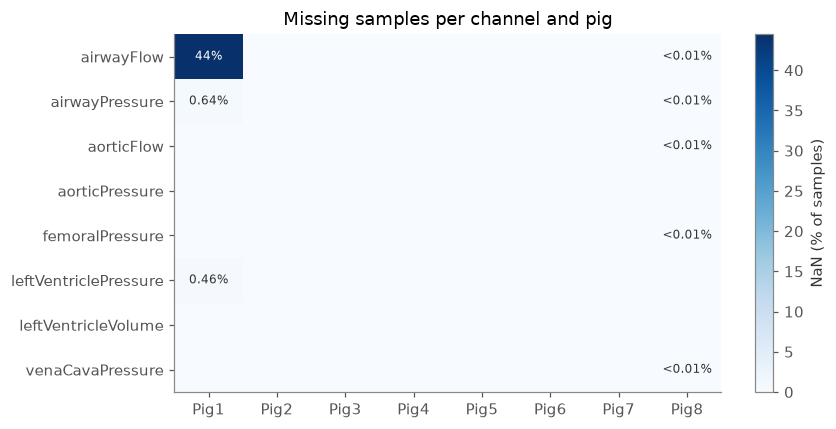

In [77]:
nan_frac = stats["nan_%"].unstack("pig")[[f"Pig{i}" for i in PIG_IDS]]

fig, ax = plt.subplots(figsize=(8, 4))
im = ax.imshow(nan_frac.values, cmap="Blues", vmin=0, vmax=max(nan_frac.values.max(), 1), aspect="auto")
ax.set_xticks(range(len(nan_frac.columns)), nan_frac.columns)
ax.set_yticks(range(len(nan_frac.index)), nan_frac.index)
ax.grid(False)
for r in range(nan_frac.shape[0]):
    for c in range(nan_frac.shape[1]):
        v = nan_frac.values[r, c]
        if v > 0:
            ax.text(c, r, f"{v:.2g}%" if v >= 0.01 else "<0.01%", ha="center", va="center", fontsize=8,
                    color="white" if v > nan_frac.values.max() / 2 else "#333333")
fig.colorbar(im, ax=ax, label="NaN (% of samples)")
ax.set_title("Missing samples per channel and pig")
fig.tight_layout()
fig.savefig(FIG_DIR / "nan_heatmap.png", dpi=150)

In [78]:
def nan_runs(x: np.ndarray) -> np.ndarray:
    """(start, length) of each contiguous NaN run."""
    m = np.concatenate([[False], np.isnan(x), [False]]).astype(np.int8)
    d = np.diff(m)
    starts, ends = np.flatnonzero(d == 1), np.flatnonzero(d == -1)
    return np.column_stack([starts, ends - starts])

for i in PIG_IDS:
    for ch in CHANNELS:
        runs = nan_runs(pigs[i][ch])
        if len(runs):
            longest = runs[:, 1].max()
            print(f"Pig{i:<2} {ch:24s} {len(runs):5d} gaps | longest {longest:,} samples "
                  f"({longest / FS:.1f} s) | first at sample {runs[0, 0]:,}")

Pig1  airwayFlow               10277 gaps | longest 499 samples (2.0 s) | first at sample 430
Pig1  airwayPressure             108 gaps | longest 317 samples (1.3 s) | first at sample 506,288
Pig1  leftVentriclePressure      494 gaps | longest 52 samples (0.2 s) | first at sample 184,527
Pig8  airwayFlow                   1 gaps | longest 1 samples (0.0 s) | first at sample 1,915,150
Pig8  airwayPressure               1 gaps | longest 1 samples (0.0 s) | first at sample 1,915,150
Pig8  aorticFlow                   1 gaps | longest 1 samples (0.0 s) | first at sample 1,915,150
Pig8  femoralPressure              1 gaps | longest 1 samples (0.0 s) | first at sample 1,915,150
Pig8  venaCavaPressure             1 gaps | longest 1 samples (0.0 s) | first at sample 1,915,150


## 5. Full-recording overview

Millions of points can't be plotted directly, so each recording is split into ~2000 bins
and the **min–max envelope** of each bin is drawn. Spikes and gaps stay visible, whereas
plain sub-sampling (`x[::k]`) would hide them.

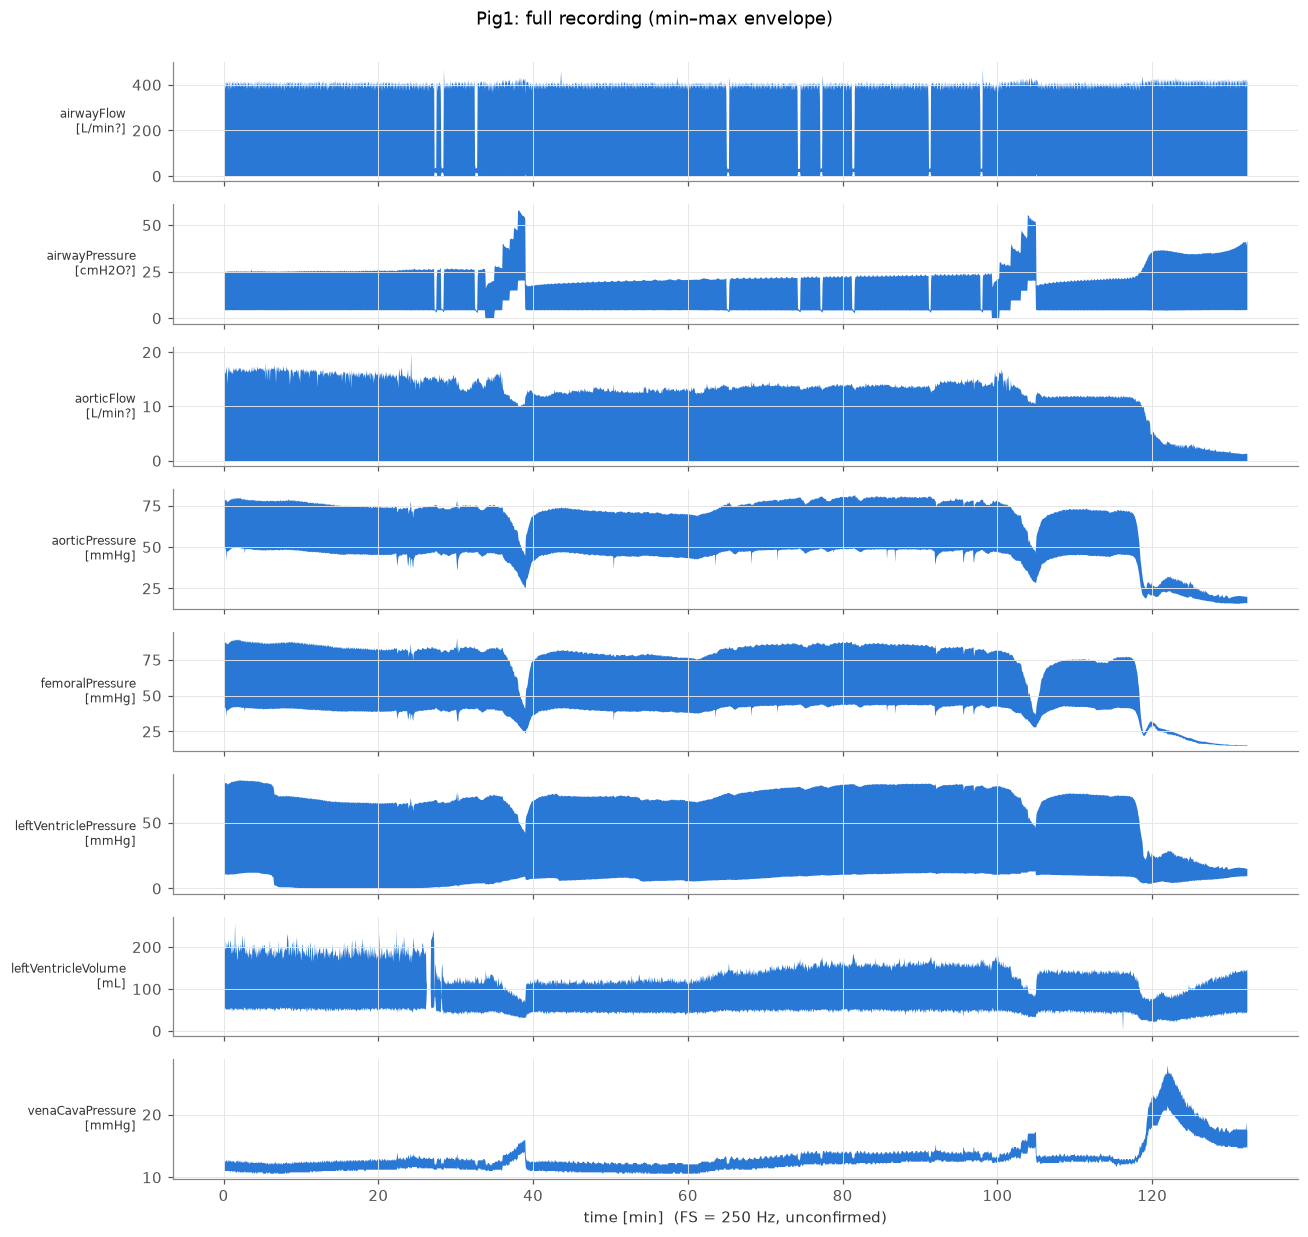

In [79]:
def envelope(x: np.ndarray, n_bins: int = 2000):
    """Bin centres (in samples), per-bin min and max (NaN-aware)."""
    k = max(len(x) // n_bins, 1)
    n = (len(x) // k) * k
    xb = x[:n].reshape(-1, k)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)   # all-NaN bins → NaN
        lo, hi = np.nanmin(xb, axis=1), np.nanmax(xb, axis=1)
    centres = np.arange(len(lo)) * k + k / 2
    return centres, lo, hi

def plot_overview(pig_id: int, save: bool = True):
    sig = pigs[pig_id]
    fig, axes = plt.subplots(len(CHANNELS), 1, figsize=(12, 1.4 * len(CHANNELS)), sharex=True)
    for ax, ch in zip(axes, CHANNELS):
        t, lo, hi = envelope(sig[ch])
        ax.fill_between(t / FS / 60, lo, hi, color=SINGLE, linewidth=0)
        ax.set_ylabel(f"{ch}\n[{UNITS[ch]}]", rotation=0, ha="right", va="center", fontsize=8)
    axes[-1].set_xlabel(f"time [min]  (FS = {FS:g} Hz, unconfirmed)")
    fig.suptitle(f"Pig{pig_id}: full recording (min–max envelope)", y=1.0)
    fig.tight_layout()
    if save:
        fig.savefig(FIG_DIR / f"overview_pig{pig_id}.png", dpi=150, bbox_inches="tight")
    return fig

plot_overview(1);

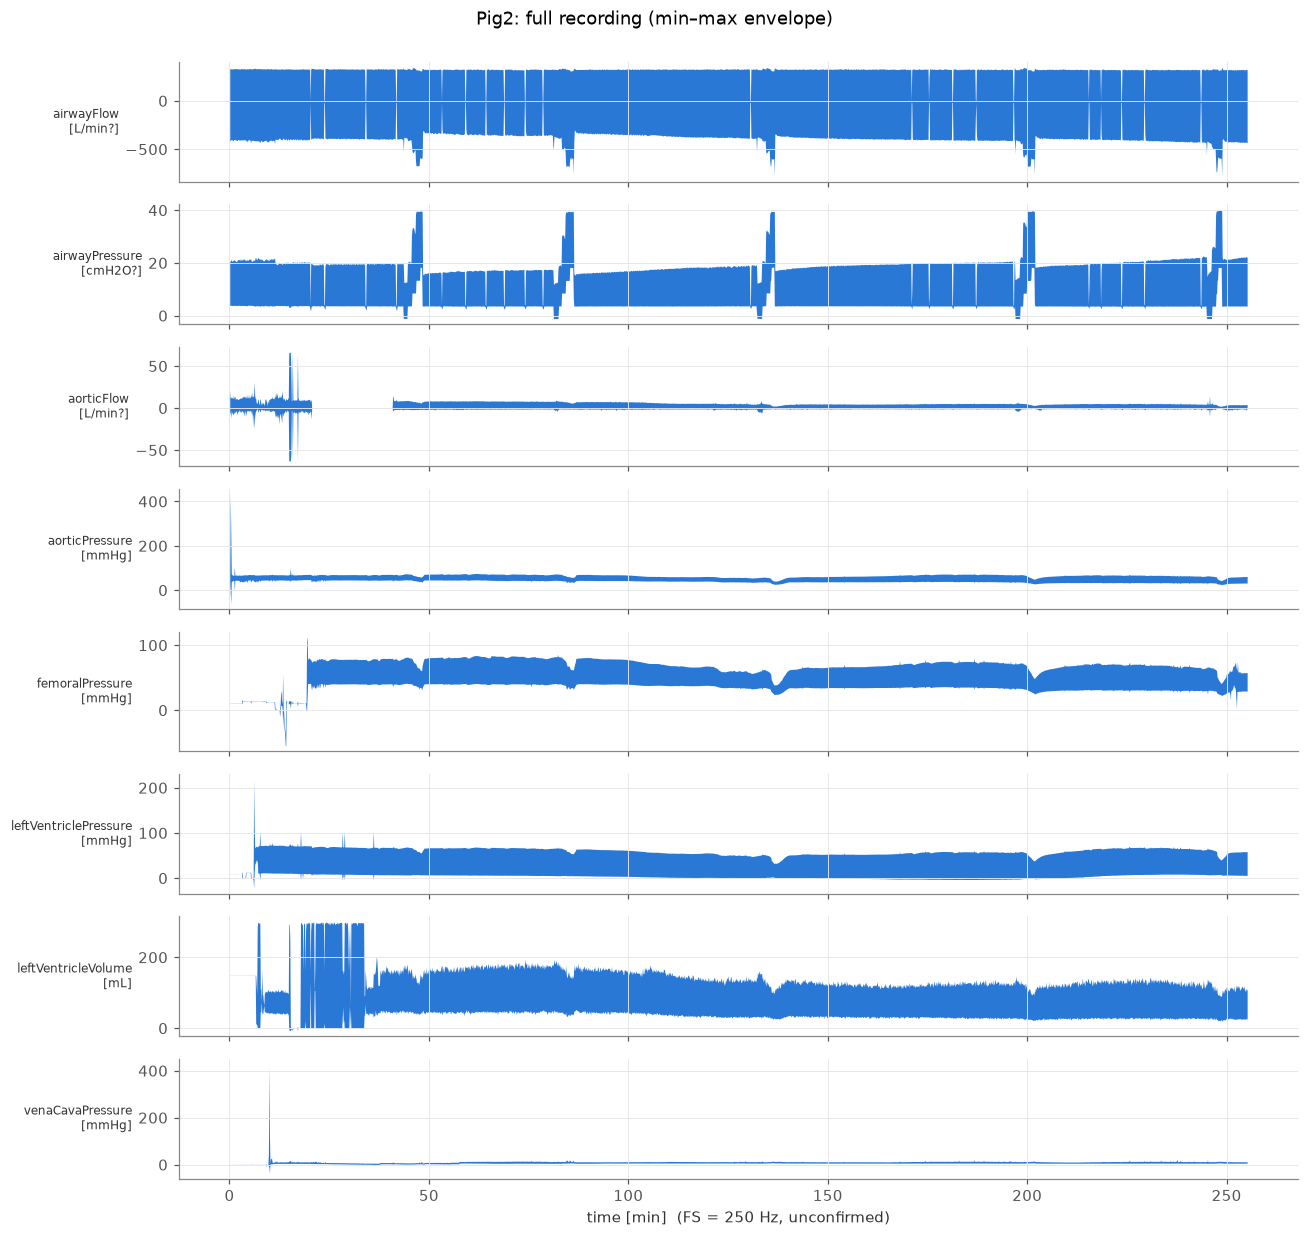

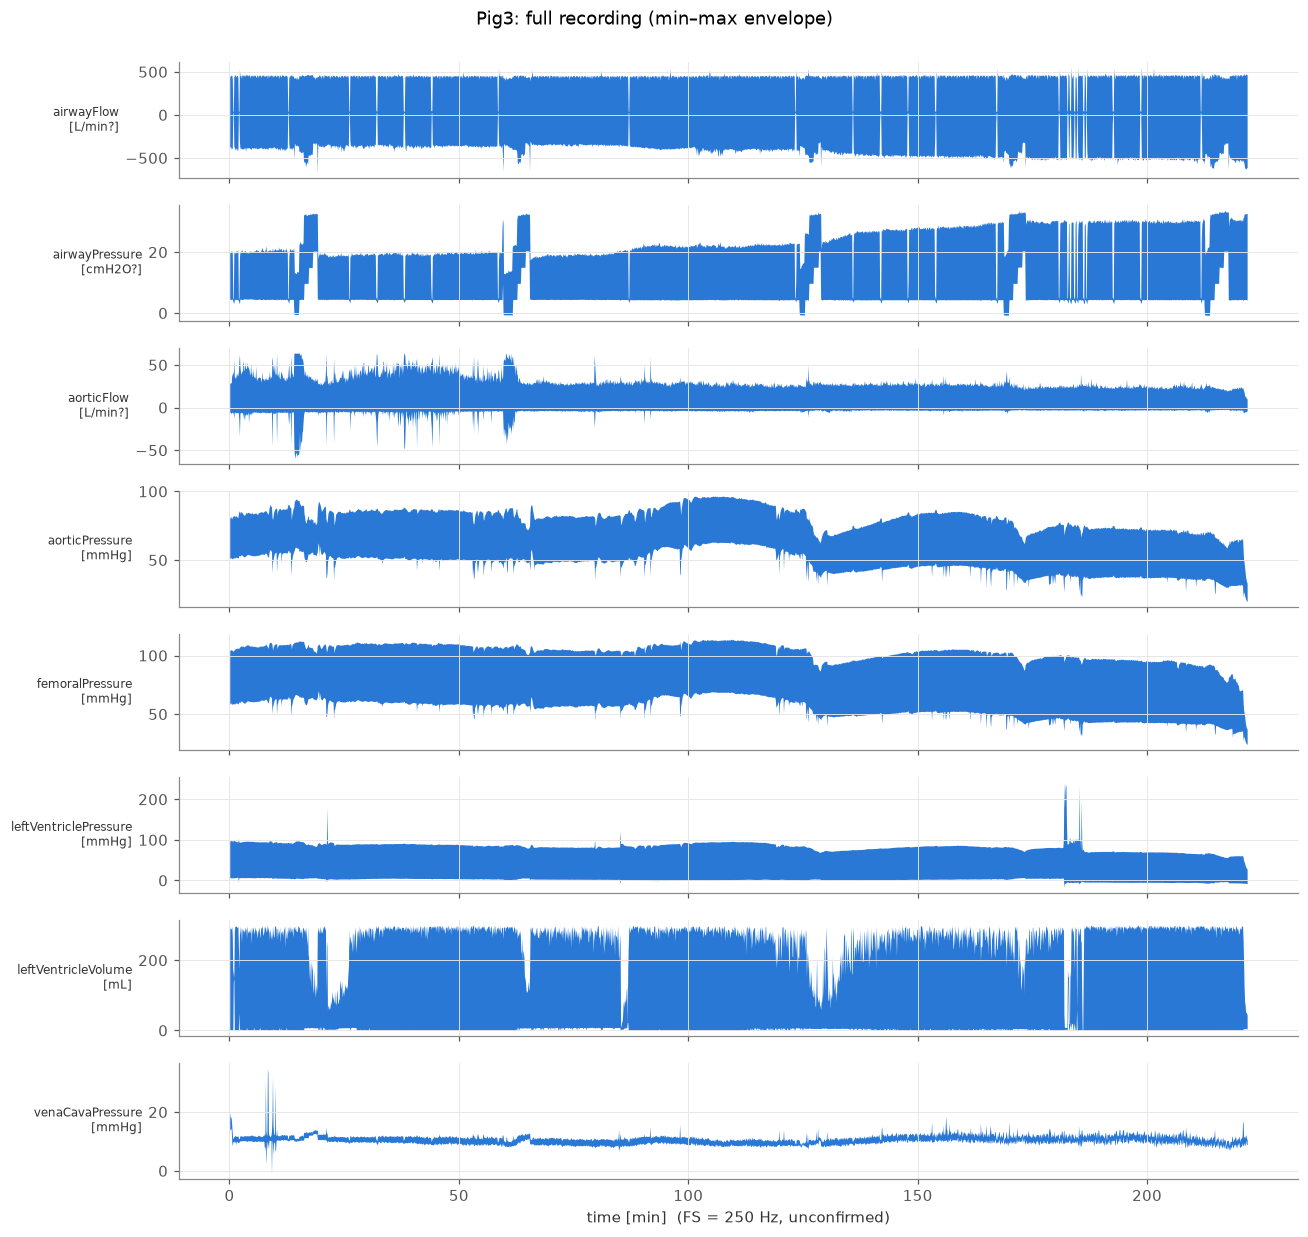

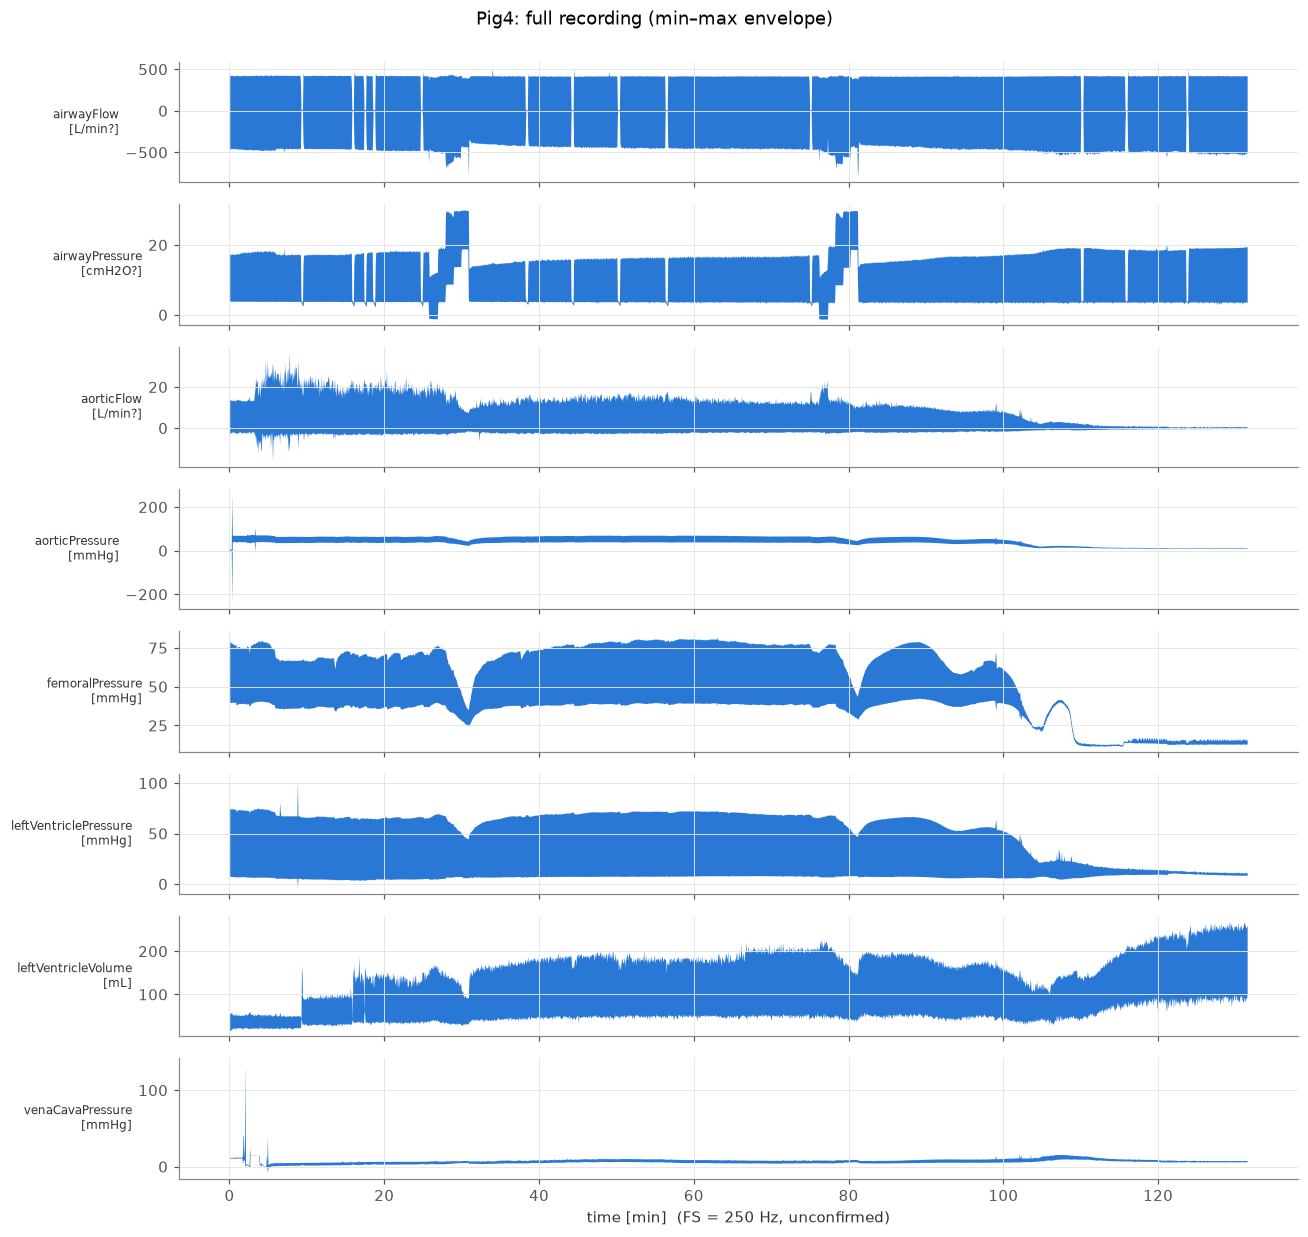

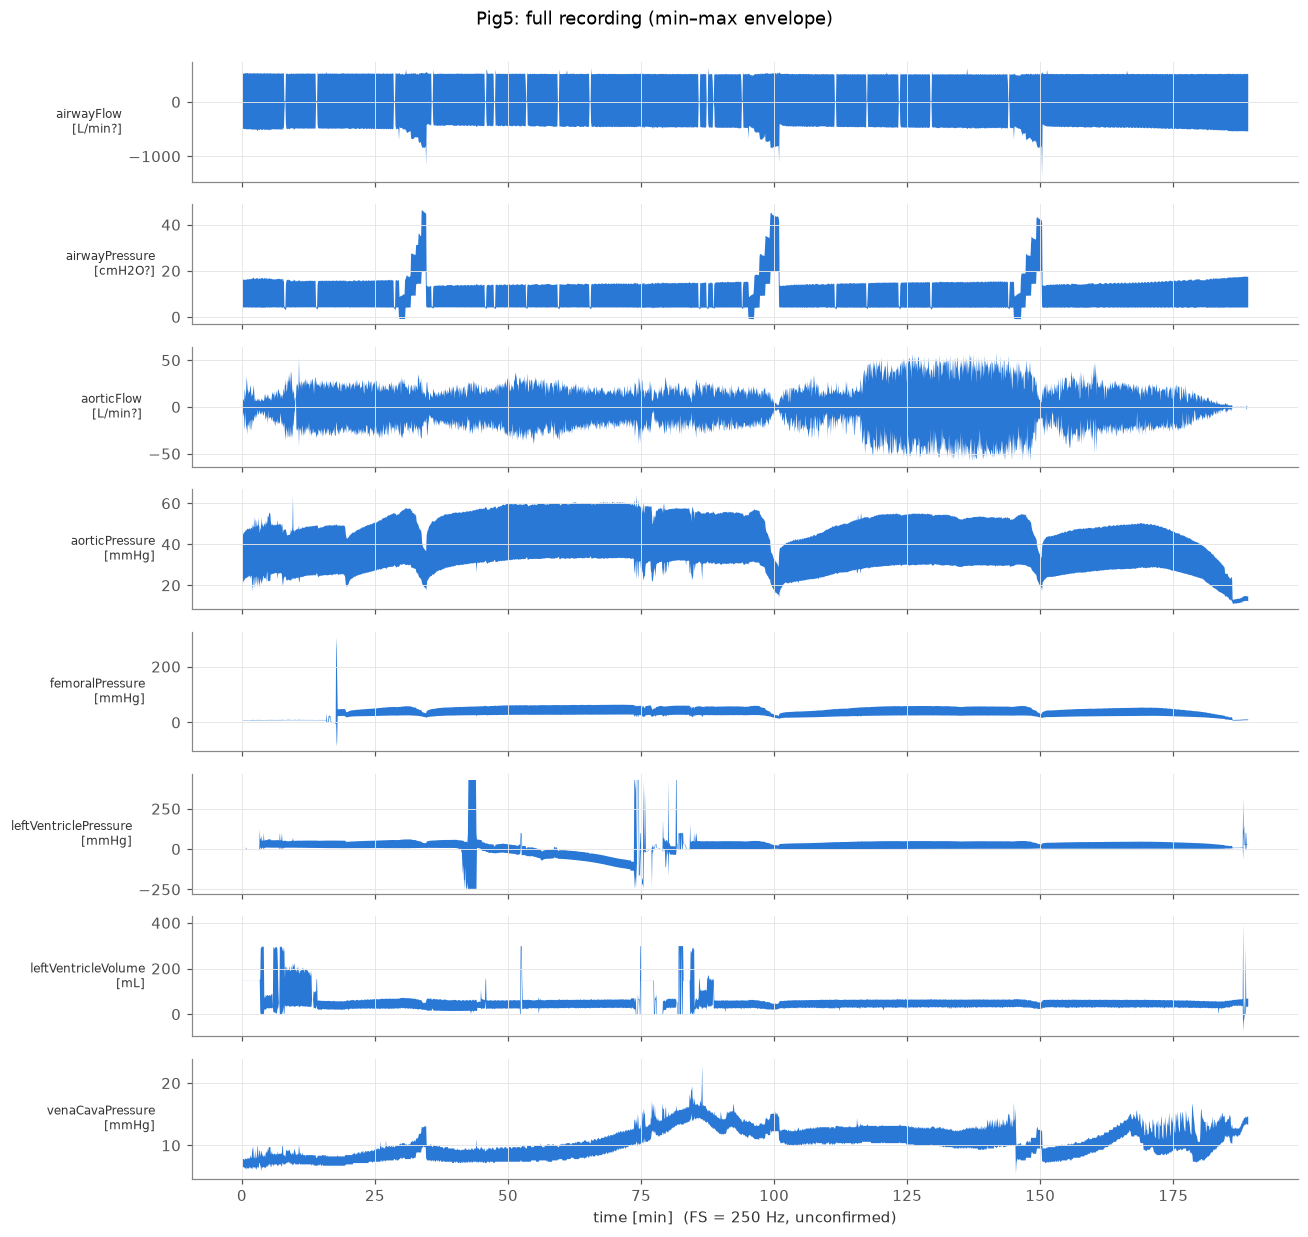

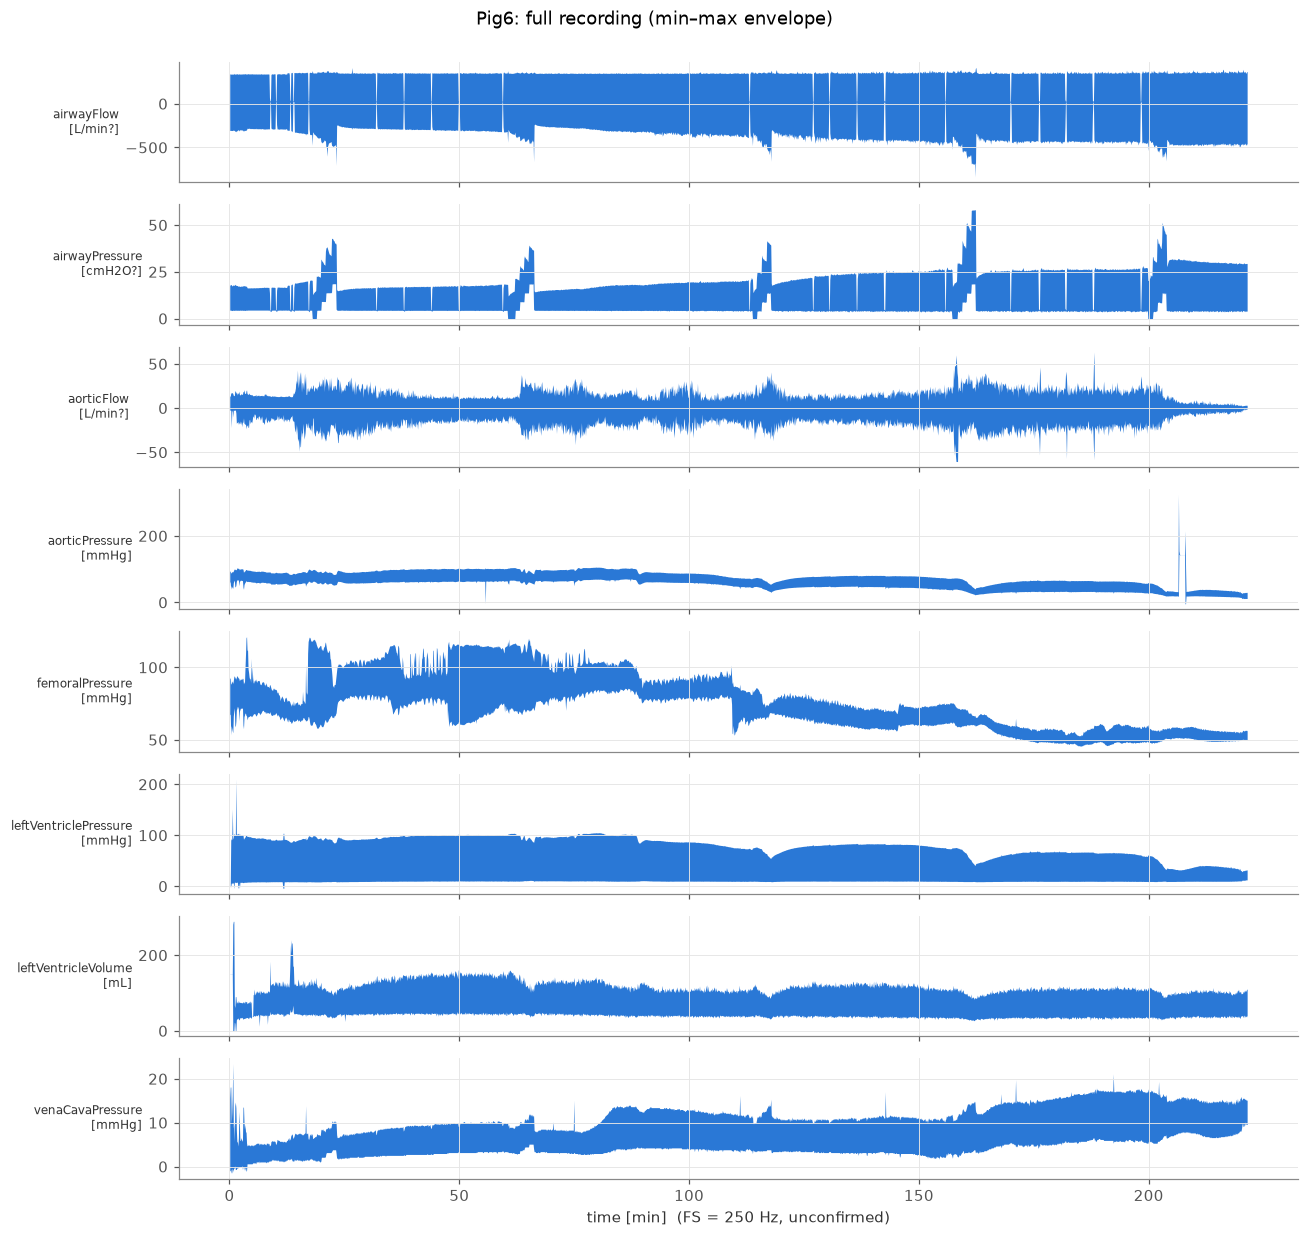

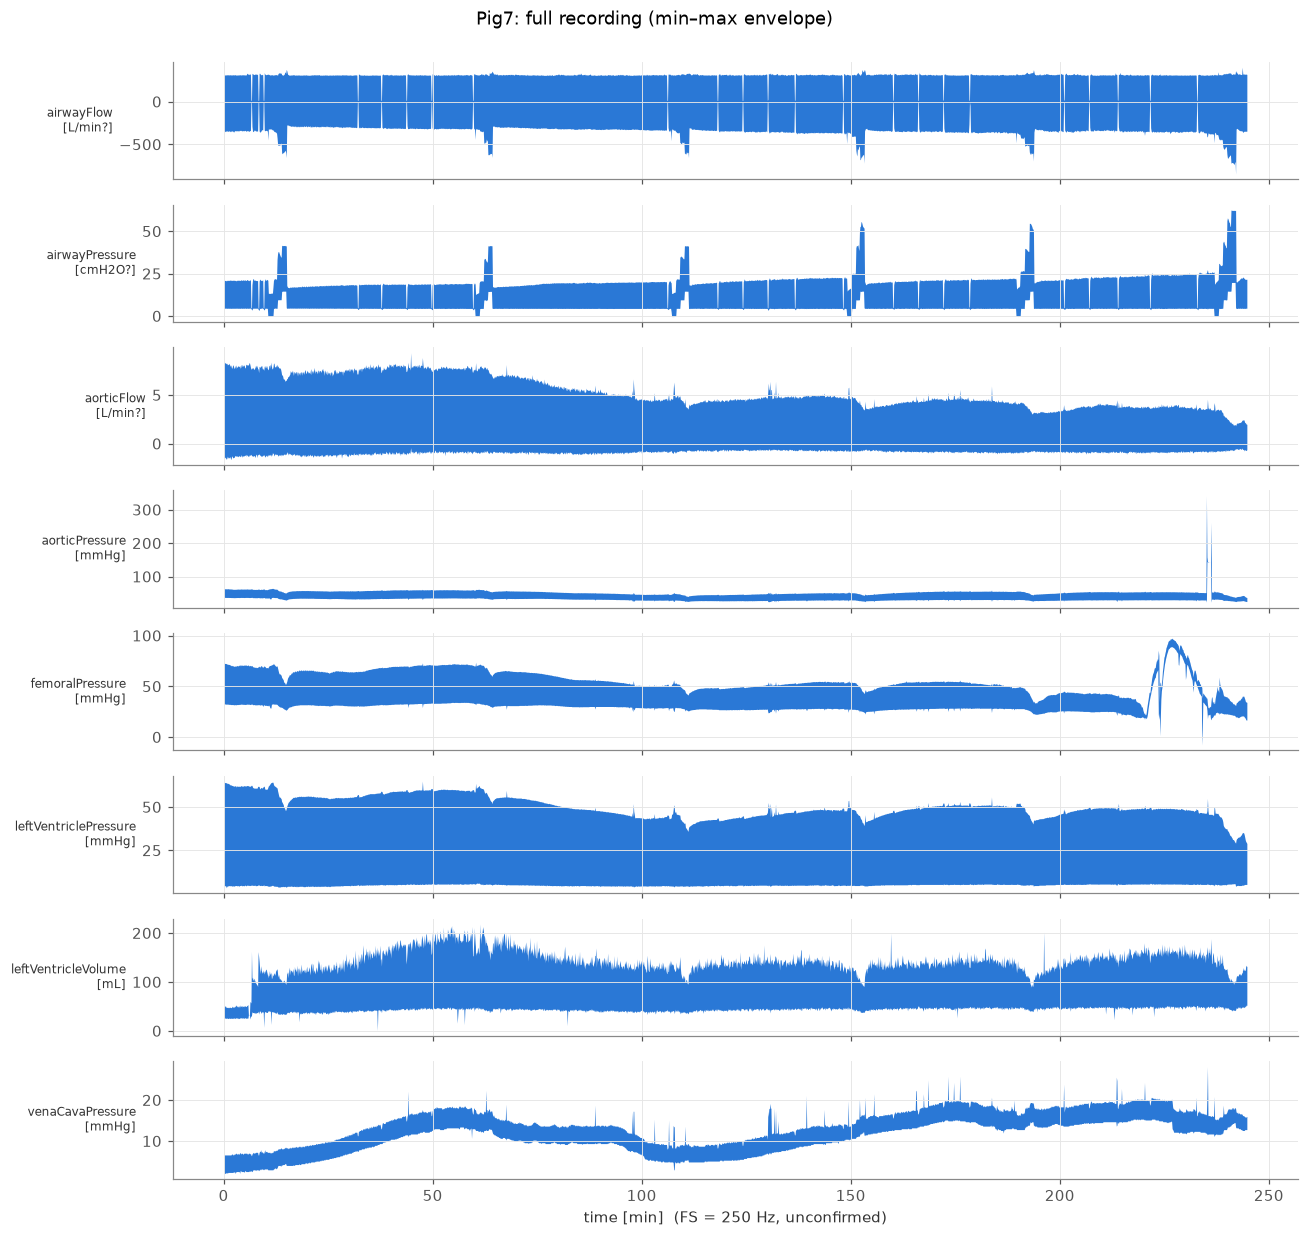

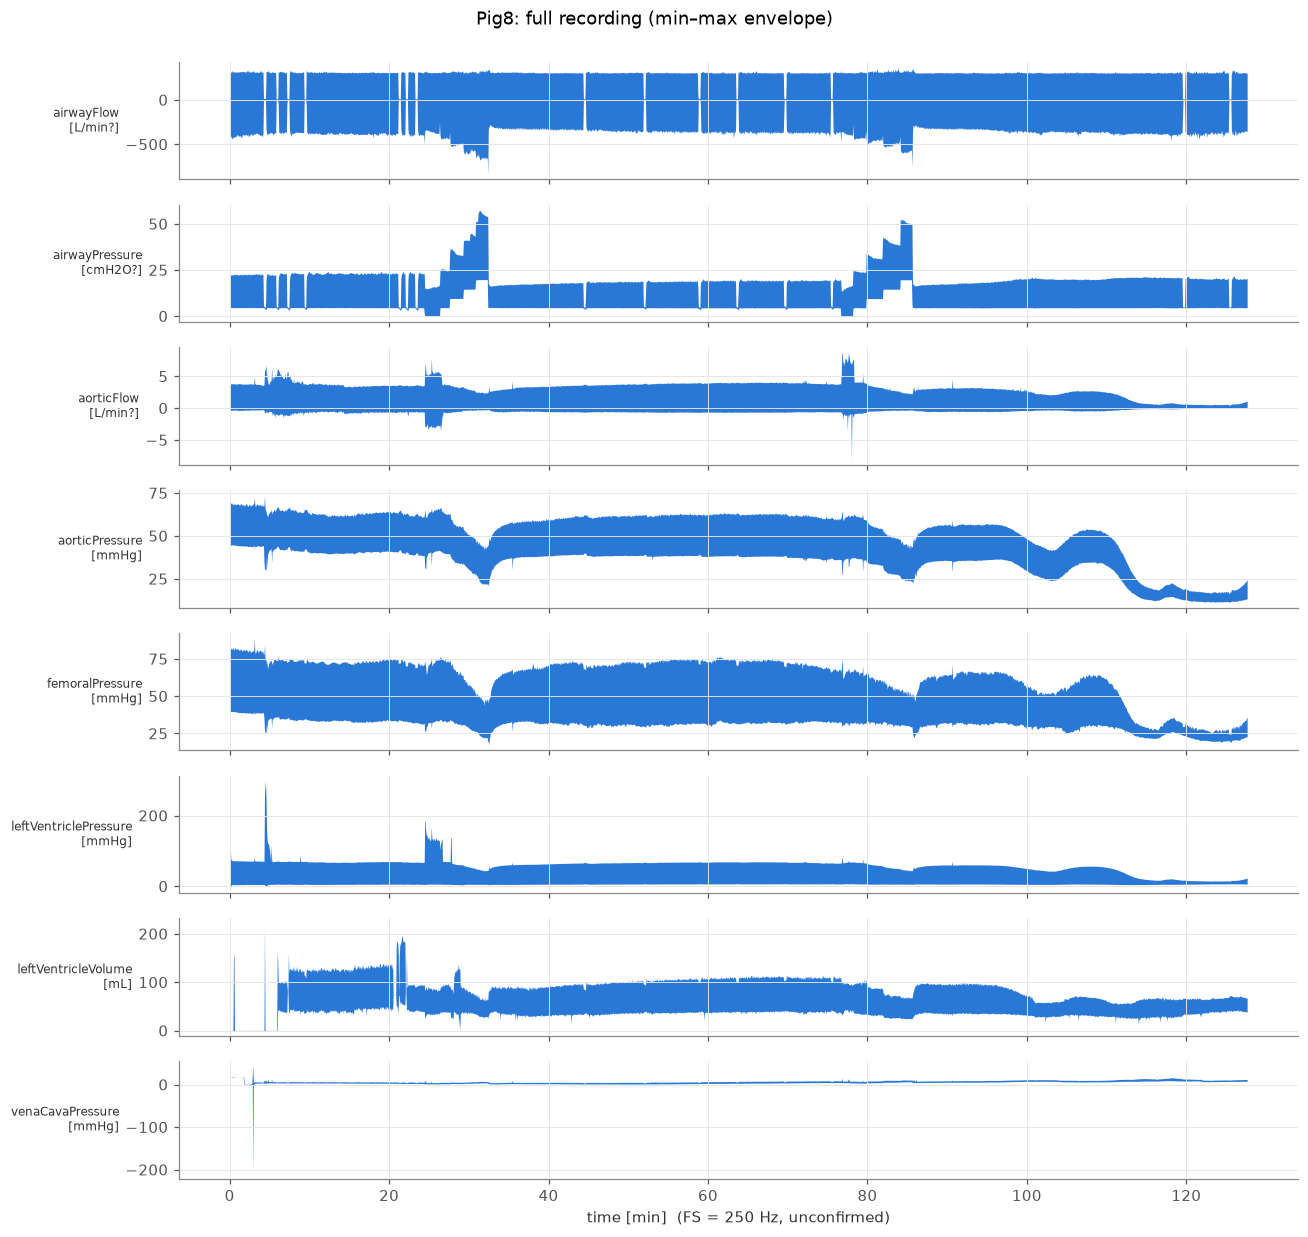

In [80]:
# All other pigs (figures are also saved to figures/exploration/)
for i in PIG_IDS[1:]:
    plot_overview(i)
    plt.show()

## 6. Zoom on a short window

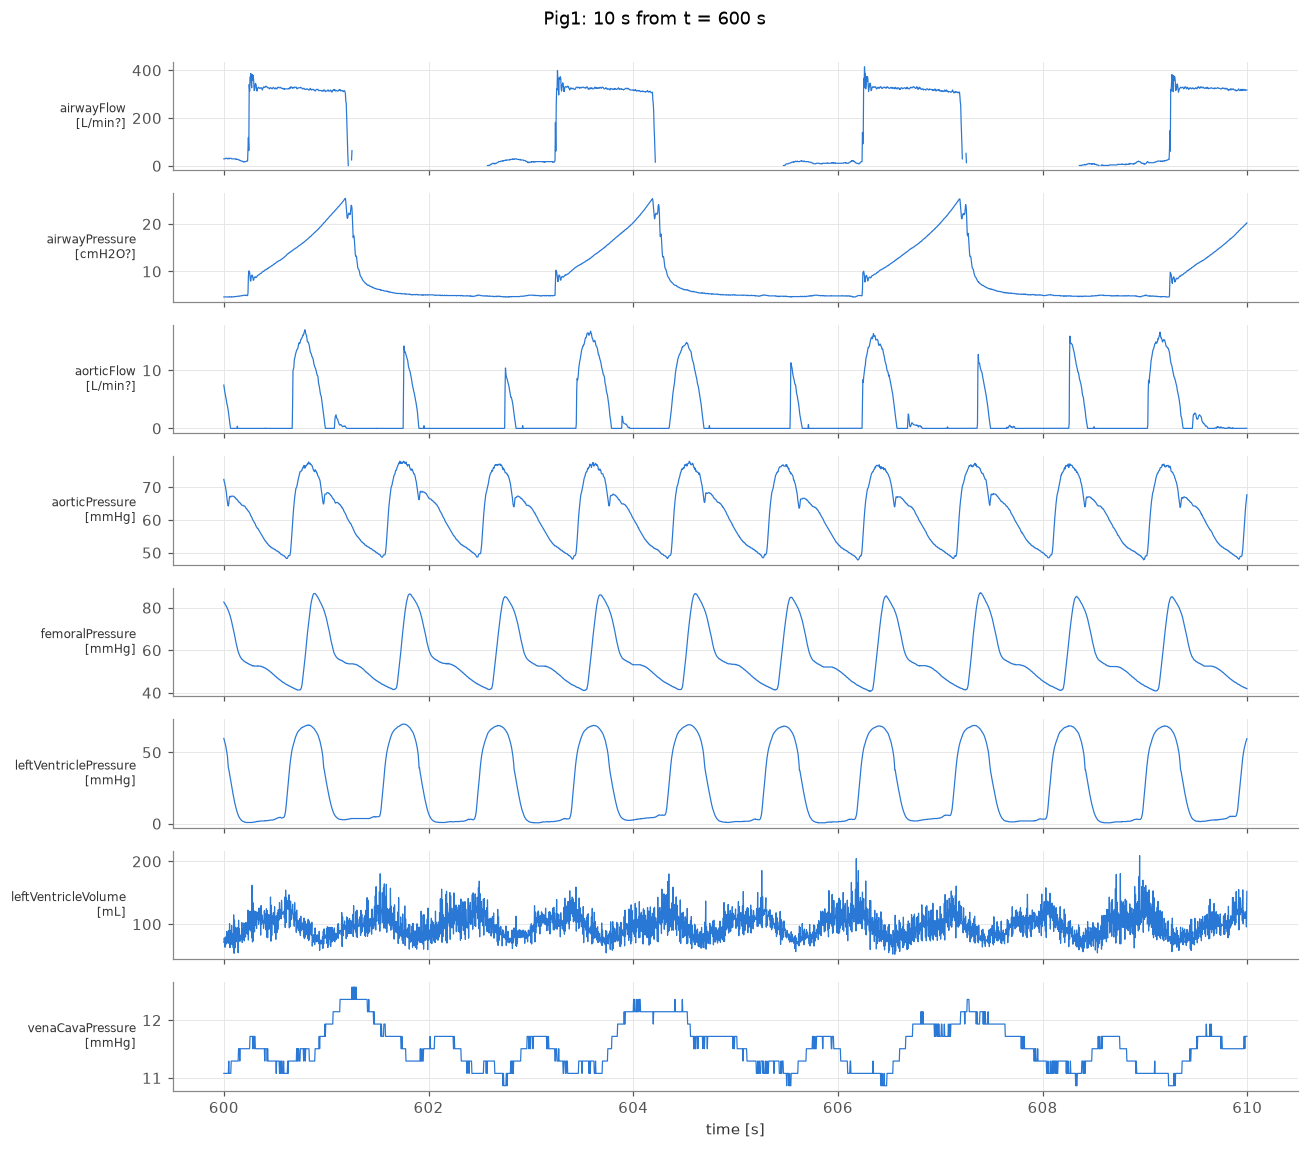

In [81]:
def plot_window(pig_id: int, start_s: float, dur_s: float = 10.0):
    sig = pigs[pig_id]
    a, b = int(start_s * FS), int((start_s + dur_s) * FS)
    t = np.arange(a, b) / FS
    fig, axes = plt.subplots(len(CHANNELS), 1, figsize=(12, 1.3 * len(CHANNELS)), sharex=True)
    for ax, ch in zip(axes, CHANNELS):
        ax.plot(t, sig[ch][a:b], color=SINGLE)
        ax.set_ylabel(f"{ch}\n[{UNITS[ch]}]", rotation=0, ha="right", va="center", fontsize=8)
    axes[-1].set_xlabel("time [s]")
    fig.suptitle(f"Pig{pig_id}: {dur_s:g} s from t = {start_s:g} s", y=1.0)
    fig.tight_layout()
    return fig

plot_window(pig_id=1, start_s=600, dur_s=10);

In a clean window you should see ~10 heartbeats in the pressure/volume/flow channels and
2–4 ventilator cycles in the airway channels. Change `pig_id` / `start_s` to inspect
anything suspicious from the overview plots.

## 7. Distributions across pigs

One panel per channel and one box per pig (whiskers at the 1st/99th percentiles,
outliers not drawn). Random sub-sampling (200k points per pig) keeps this fast.
Different medians mean the **pigs have different baselines**, which matters for normalisation
(per pig vs global) and for leave-one-pig-out evaluation.

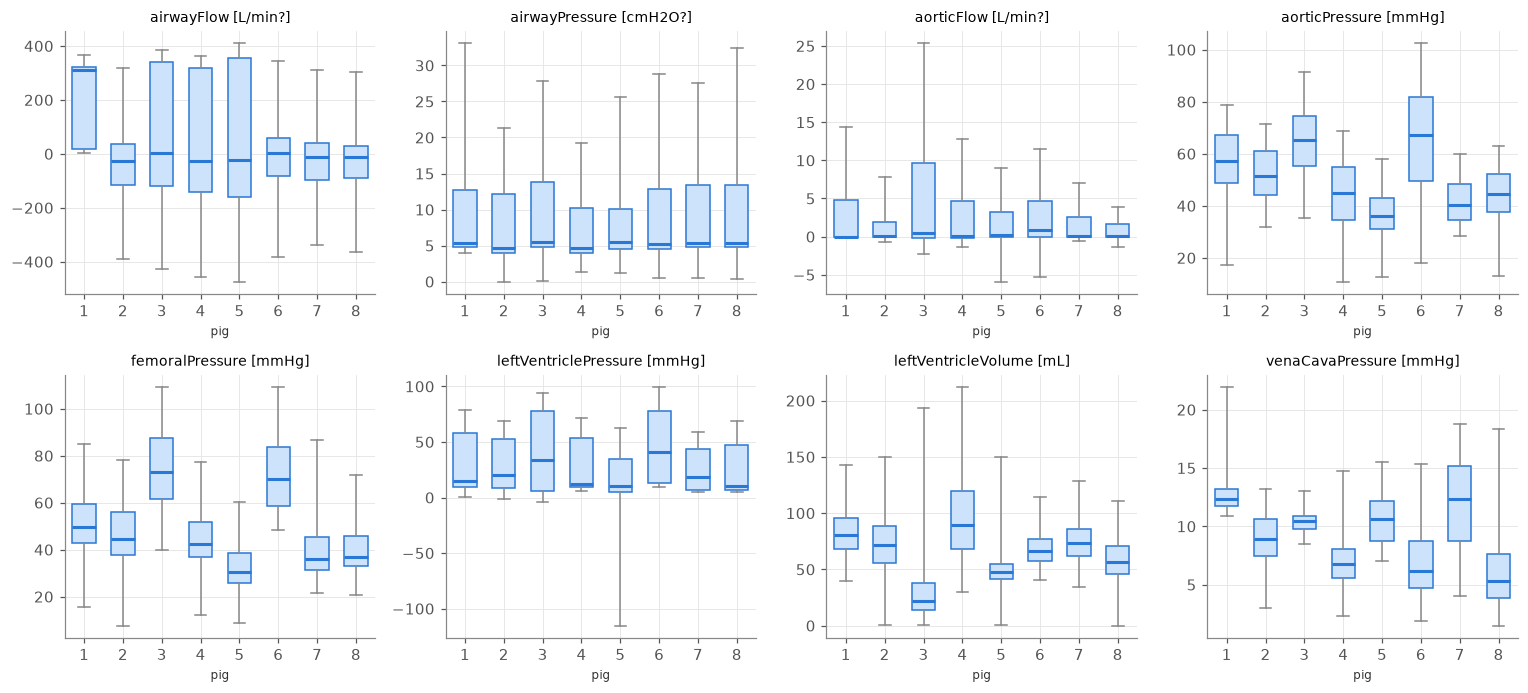

In [82]:
rng = np.random.default_rng(0)

def subsample(x, n=200_000):
    x = x[~np.isnan(x)]
    return x if len(x) <= n else rng.choice(x, n, replace=False)

ncols = 4
nrows = int(np.ceil(len(CHANNELS) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3.2 * nrows))
for ax, ch in zip(axes.flat, CHANNELS):
    data = [subsample(pigs[i][ch]) for i in PIG_IDS]
    ax.boxplot(data, whis=(1, 99), showfliers=False, widths=0.6,
               patch_artist=True,
               boxprops=dict(facecolor="#cde2fb", edgecolor=SINGLE),
               medianprops=dict(color=SINGLE, linewidth=2),
               whiskerprops=dict(color="#888888"), capprops=dict(color="#888888"))
    ax.set_xticks(range(1, len(PIG_IDS) + 1), [str(i) for i in PIG_IDS])
    ax.set_title(f"{ch} [{UNITS[ch]}]", fontsize=9)
    ax.set_xlabel("pig", fontsize=8)
for ax in axes.flat[len(CHANNELS):]:
    ax.set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "distributions.png", dpi=150)

## 8. Out-of-range values (artifacts)

Rough **physiological plausibility bounds** for anaesthetised pigs. These are a starting point
for flagging artifacts, not ground truth, so adjust them after looking at the plots.

In [83]:
BOUNDS = {
    "aorticPressure":        (0, 250),
    "femoralPressure":       (0, 250),
    "leftVentriclePressure": (-20, 250),
    "venaCavaPressure":      (-10, 40),
    "leftVentricleVolume":   (0, 350),
    "aorticFlow":            (-30, 60),
    "airwayPressure":        (-5, 60),
    "airwayFlow":            (-1500, 1500),
}

out = pd.DataFrame(
    {f"Pig{i}": {ch: 100 * np.mean((pigs[i][ch] < lo) | (pigs[i][ch] > hi))
                 for ch, (lo, hi) in BOUNDS.items()} for i in PIG_IDS}
)
out.style.format("{:.3f}").background_gradient(cmap="Blues", axis=None)

,Pig1,Pig2,Pig3,Pig4,Pig5,Pig6,Pig7,Pig8
aorticPressure,0.000,0.014,0.000,0.005,0.000,0.016,0.000,0.000
femoralPressure,0.000,0.306,0.000,0.000,0.124,0.000,0.003,0.000
leftVentriclePressure,0.000,0.000,0.000,0.000,11.551,0.000,0.000,0.001
venaCavaPressure,0.000,0.001,0.000,0.001,0.000,0.000,0.000,0.007
leftVentricleVolume,0.000,1.019,0.000,0.000,0.988,0.015,0.000,3.541
aorticFlow,0.000,0.016,0.015,0.000,0.034,0.008,0.000,0.000
airwayPressure,0.000,0.000,0.000,0.000,0.000,0.000,0.006,0.000
airwayFlow,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000


In [84]:
# Flat segments: a disconnected sensor often outputs a constant value
def longest_flat_run(x: np.ndarray) -> int:
    same = np.concatenate([[False], np.diff(x) == 0, [False]]).astype(np.int8)
    d = np.diff(same)
    starts, ends = np.flatnonzero(d == 1), np.flatnonzero(d == -1)
    return int((ends - starts).max() + 1) if len(starts) else 1

flat = pd.DataFrame({f"Pig{i}": {ch: longest_flat_run(pigs[i][ch]) / FS for ch in CHANNELS}
                     for i in PIG_IDS})
print("Longest constant segment per channel [s]:")
flat.round(1)

Longest constant segment per channel [s]:


,Pig1,Pig2,Pig3,Pig4,Pig5,Pig6,Pig7,Pig8
airwayFlow,0.2,0.4,0.2,1.0,0.2,0.3,0.3,0.3
airwayPressure,0.4,0.4,0.3,0.3,0.4,0.3,0.4,0.3
aorticFlow,0.8,0.9,0.1,0.3,0.4,0.2,0.6,0.3
aorticPressure,0.5,0.4,0.1,0.6,0.8,7.4,22.2,0.2
femoralPressure,1.0,2.0,0.1,0.8,1.0,1.1,0.3,0.3
leftVentriclePressure,0.4,23.0,0.5,0.6,11.0,3.5,0.2,0.5
leftVentricleVolume,23.4,7.7,6.4,1.3,8.1,9.3,1.1,4.0
venaCavaPressure,0.9,7.5,0.5,3.1,1.0,0.5,0.2,1.6


## 9. Periodicity and sampling rate

The **autocorrelation** of a periodic signal peaks at multiples of its period (in samples).
- Heartbeat → use `aorticPressure`.
- Ventilator cycle → use `airwayPressure`.

Combined with plausible rates (pig heart ~60–120 bpm, ventilator ~12–25 breaths/min),
this bounds `FS`. The dataset paper should give the exact value.

In [85]:
def dominant_period(x: np.ndarray, start: int = 100_000, n: int = 60_000, min_lag: int = 50) -> int:
    seg = x[start:start + n].astype(np.float64)
    seg = np.nan_to_num(seg - np.nanmean(seg))
    ac = signal.correlate(seg, seg, mode="full", method="fft")[len(seg) - 1:]
    ac /= ac[0]
    peaks, _ = signal.find_peaks(ac[min_lag:], height=0.3)
    return int(peaks[0] + min_lag) if len(peaks) else -1

per = pd.DataFrame({
    "heart_period_samples":  {f"Pig{i}": dominant_period(pigs[i]["aorticPressure"])  for i in PIG_IDS},
    "breath_period_samples": {f"Pig{i}": dominant_period(pigs[i]["airwayPressure"], min_lag=300) for i in PIG_IDS},
})
for fs in (100, 200, 250, 500):
    per[f"HR@{fs}Hz [bpm]"] = 60 * fs / per["heart_period_samples"]
    per[f"RR@{fs}Hz [/min]"] = 60 * fs / per["breath_period_samples"]
per.round(1)

,heart_period_samples,breath_period_samples,HR@100Hz [bpm],RR@100Hz [/min],HR@200Hz [bpm],RR@200Hz [/min],HR@250Hz [bpm],RR@250Hz [/min],HR@500Hz [bpm],RR@500Hz [/min]
Pig1,232,750,25.9,8.0,51.7,16.0,64.7,20.0,129.3,40.0
Pig2,202,600,29.7,10.0,59.4,20.0,74.3,25.0,148.5,50.0
Pig3,202,600,29.7,10.0,59.4,20.0,74.3,25.0,148.5,50.0
Pig4,178,600,33.7,10.0,67.4,20.0,84.3,25.0,168.5,50.0
Pig5,190,600,31.6,10.0,63.2,20.0,78.9,25.0,157.9,50.0
Pig6,164,600,36.6,10.0,73.2,20.0,91.5,25.0,182.9,50.0
Pig7,202,600,29.7,10.0,59.4,20.0,74.3,25.0,148.5,50.0
Pig8,189,750,31.7,8.0,63.5,16.0,79.4,20.0,158.7,40.0


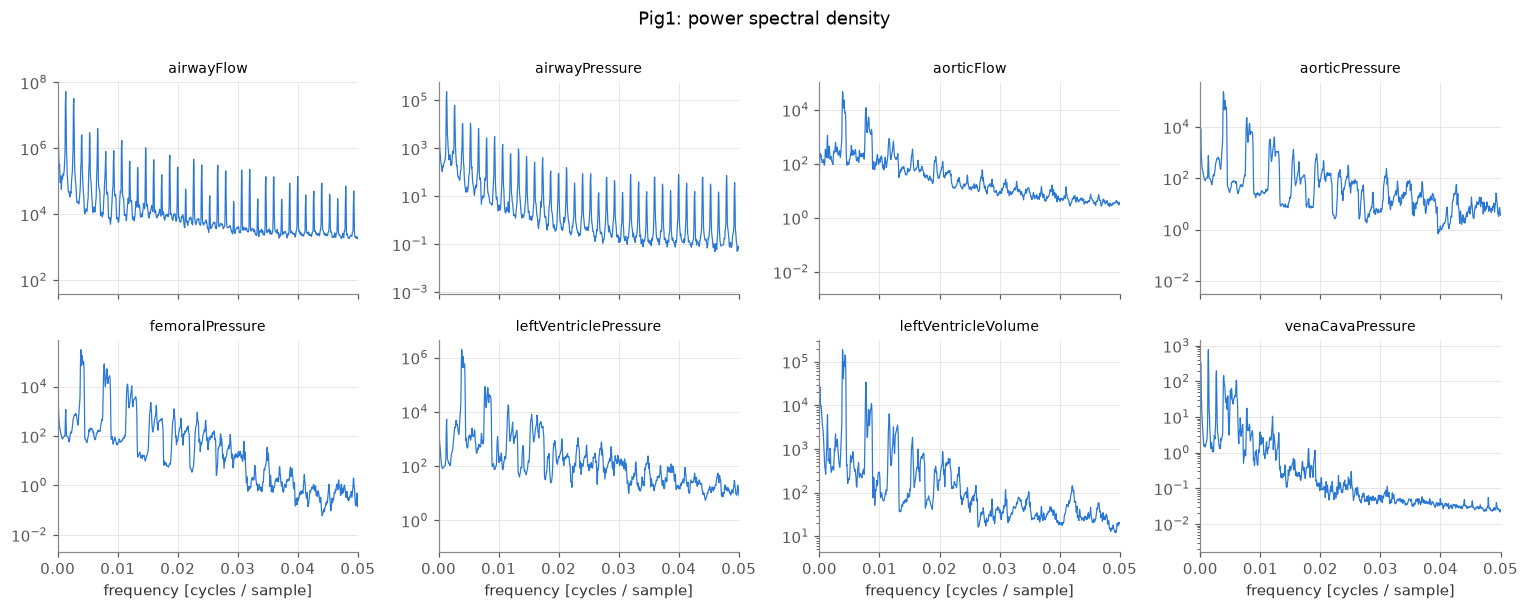

In [86]:
# Power spectrum (Welch) per channel for one pig, frequency axis in cycles/sample
# → independent of FS; multiply by FS to get Hz once it is known.
PIG = 1
fig, axes = plt.subplots(2, 4, figsize=(14, 5.5), sharex=True)
for ax, ch in zip(axes.flat, CHANNELS):
    x = pigs[PIG][ch]
    x = np.nan_to_num(x - np.nanmean(x))
    f, pxx = signal.welch(x, fs=1.0, nperseg=2**14)
    ax.semilogy(f, pxx, color=SINGLE)
    ax.set_xlim(0, 0.05)
    ax.set_title(ch, fontsize=9)
for ax in axes[-1]:
    ax.set_xlabel("frequency [cycles / sample]")
fig.suptitle(f"Pig{PIG}: power spectral density", y=1.0)
fig.tight_layout()

## Findings so far (fill in as you explore)

- **Format**: all 8 files are MAT v5 structs with the same 8 channels. **Channel order differs from Pig3 on**, so always index by name.
- **Lengths**: 1.9M to 3.8M samples per pig, equal across channels within a pig.
- **Sampling rate**: not stored; the autocorrelation table above bounds it. *Confirm from the paper.*
- **Missing data**: Pig1 `airwayFlow` is ~44 % NaN in ~10k short gaps, and it never goes negative. The zoom plot shows the gaps fall in **expiration**, so only inspiratory flow seems to be recorded for Pig1. Pig1 `airwayPressure` / `leftVentriclePressure` have small gaps (≤ ~1 s). Pig8 is missing only the **last sample** in 5 channels, so just drop it.
- **Sampling rate**: breathing is exactly 600 samples per cycle (750 for Pig1), which points to a fixed ventilator setting. At 250 Hz that gives 20–25 breaths/min and a heart rate of ~65–90 bpm (plausible). At 200 Hz the heart rate would be ~52–73 bpm. Still **to be confirmed**.
- **Experimental protocol is visible**: Pig1 shows step-wise airway-pressure increases (~35–40 min and ~100–105 min, recruitment-manoeuvre-like) with simultaneous drops in aortic pressure and flow, and a terminal decline after ~118 min. Segments like these may need labelling or excluding, depending on the task.
- **Artifacts**: large spikes in several channels (e.g. Pig2 `aorticPressure`/`venaCavaPressure` up to ~430, Pig5 `leftVentriclePressure` from −244 to 431). These need flagging or clipping before training.
- **Flat segments**: some channels hold a constant value for >20 s (Pig2 `leftVentriclePressure`, Pig7 `aorticPressure`, Pig1 `leftVentricleVolume`), which looks like sensor disconnection or a saturated signal.
- **Noise**: `leftVentricleVolume` (conductance catheter) is much noisier than the pressures, so it probably needs low-pass filtering.
- **Quantisation**: some channels have very few distinct values (Pig1 `venaCavaPressure`, Pig5 `femoralPressure`), so check for low ADC resolution or flat segments.
- **Between-pig shifts**: medians differ clearly between pigs, so think about per-pig normalisation and leave-one-pig-out splits.

In [71]:
import os 
data_path=os.path.join(Path.cwd().parents[0],'data/processed/pigs_useful.h5')
print(data_path)


/Users/mboukaf/ThesisMB/Codes/PigsBF/data/processed/pigs_useful.h5


In [72]:
import h5py
file=h5py.File(data_path,'r')

In [78]:
print(file.keys())

<KeysViewHDF5 ['pig4', 'pig6', 'pig7', 'pig8']>


In [76]:
file.visit(print)

pig4
pig4/signals
pig4/valid
pig6
pig6/signals
pig6/valid
pig7
pig7/signals
pig7/valid
pig8
pig8/signals
pig8/valid


In [80]:
dict(file.attrs)

{'bound_margin_s': np.float64(0.5),
 'bounds': '{"aorticPressure": [0, 250], "aorticFlow": [-30, 60], "femoralPressure": [0, 250], "leftVentriclePressure": [-20, 250], "leftVentricleVolume": [0, 350], "venaCavaPressure": [-10, 40], "airwayPressure": [-5, 60], "airwayFlow": [-1500, 1500]}',
 'channels': array(['aorticPressure', 'aorticFlow', 'femoralPressure',
        'leftVentriclePressure', 'leftVentricleVolume', 'venaCavaPressure',
        'airwayPressure', 'airwayFlow'], dtype=object),
 'created': '2026-10-05T16:26:43',
 'flat_min_s': np.float64(1.0),
 'fs': np.int64(250),
 'source': 'OSF archive, Cushway et al. PLOS ONE 2024 (doi:10.1371/journal.pone.0306925)',
 'units': array(['mmHg', 'L/min', 'mmHg', 'mmHg', 'mL', 'mmHg', 'cmH2O', 'mL/s'],
       dtype=object)}